# 05 - Evaluasi Model

Membaca hasil yang dihasilkan `retrain.py` (`results/` dan `models/`). Sel-sel di bawah tidak menghitung ulang model, sehingga cepat dan konsisten dengan aplikasi.


In [1]:
import sys, os
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)
import pandas as pd, numpy as np
from IPython.display import Image, display
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 40)

In [2]:
import json, joblib
meta = json.load(open('models/model_metadata.json'))
print(json.dumps({k: meta[k] for k in ['model_name','train_period','validation_period','test_period','metrics_test','naive_baseline_test']}, indent=1))

{
 "model_name": "Random Forest | global | ratio",
 "train_period": [
  "2016-10-01",
  "2023-12-01"
 ],
 "validation_period": [
  "2024-01-01",
  "2024-12-01"
 ],
 "test_period": [
  "2025-01-01",
  "2026-09-01"
 ],
 "metrics_test": {
  "MAE": 1903.556361221958,
  "RMSE": 3626.7303392310914,
  "R2": 0.9079605449182881,
  "MAPE_%": 5.178489339884776
 },
 "naive_baseline_test": {
  "MAE": 1838.0512986545796,
  "RMSE": 3725.779638694306,
  "R2": 0.9028645317819249,
  "MAPE_%": 4.9116704709355075
 }
}


In [3]:
r = pd.read_csv('results/evaluation_metrics.csv')
r[r.split=='test'].sort_values('MAE')[['model','MAE','RMSE','R2','MAPE_%']].round(3)

,model,MAE,RMSE,R2,MAPE_%
25,Naive Forecast,1838.051,3725.780,0.903,4.912
15,Random Forest | global | ratio,1903.556,3626.730,0.908,5.178
17,XGBoost | global | ratio,1949.383,3609.115,0.909,5.368
13,Linear Regression | global | ratio,1979.929,3628.960,0.908,5.511
7,Linear Regression | separate | level,1989.237,3533.812,0.913,5.590
3,Random Forest | global | level,2002.967,3635.919,0.907,5.648
21,Random Forest | separate | ratio,2016.724,3705.608,0.904,5.700
5,XGBoost | global | level,2026.470,3701.073,0.904,5.610
1,Linear Regression | global | level,2036.957,3581.927,0.910,5.928
23,XGBoost | separate | ratio,2053.516,3662.081,0.906,5.904


In [4]:
c = pd.read_csv('results/evaluation_by_commodity.csv')
c[c.model.isin([meta['model_name'],'Naive Forecast'])].round(2)

,commodity,model,n,MAE,RMSE,R2,MAPE_%
7,eggs,Random Forest | global | ratio,3948,1489.49,2111.02,0.75,5.02
12,eggs,Naive Forecast,3948,1328.53,2082.87,0.76,4.47
20,garlic,Random Forest | global | ratio,4008,2535.69,3649.75,0.79,6.39
25,garlic,Naive Forecast,4008,2133.91,3548.49,0.80,5.34
33,meat_chicken,Random Forest | global | ratio,3922,2667.14,3554.69,0.74,7.35
38,meat_chicken,Naive Forecast,3922,2537.53,3500.17,0.75,7.02
46,oil,Random Forest | global | ratio,3965,470.17,877.07,0.88,2.07
51,oil,Naive Forecast,3965,263.07,645.43,0.94,1.15
59,onions,Random Forest | global | ratio,4004,5632.28,7752.96,0.41,12.45
64,onions,Naive Forecast,4004,6220.53,8171.51,0.34,14.31


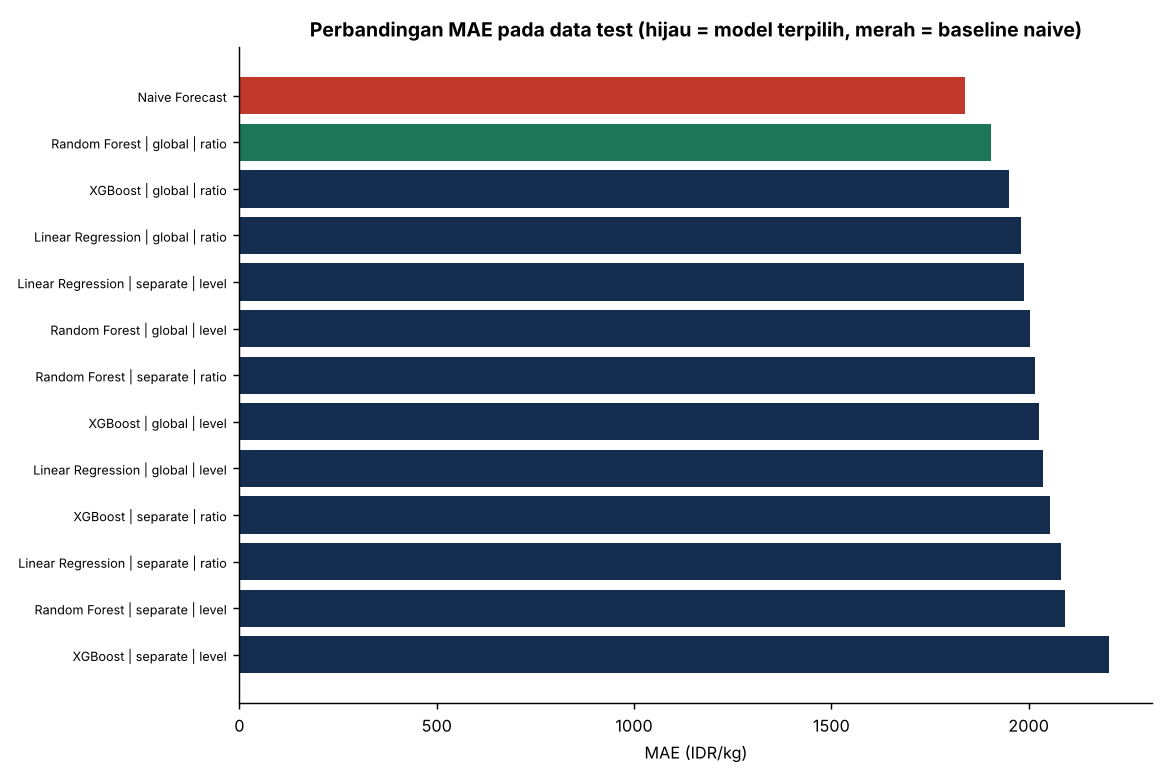

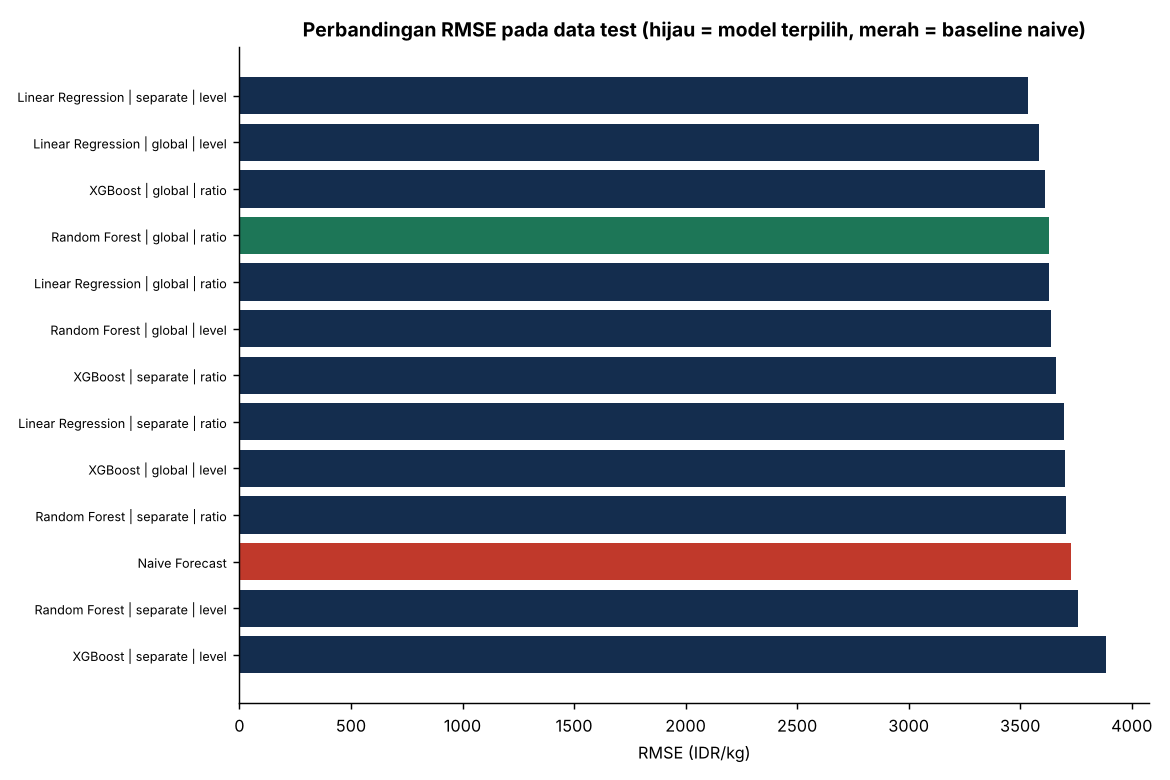

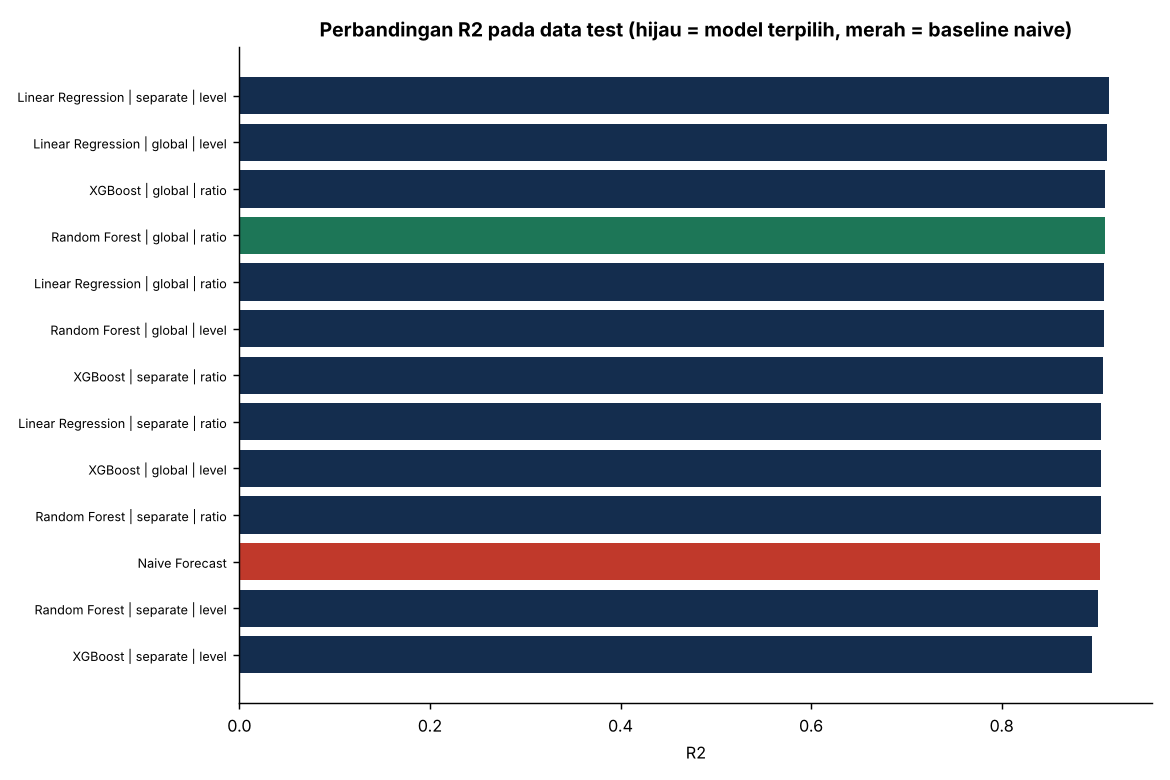

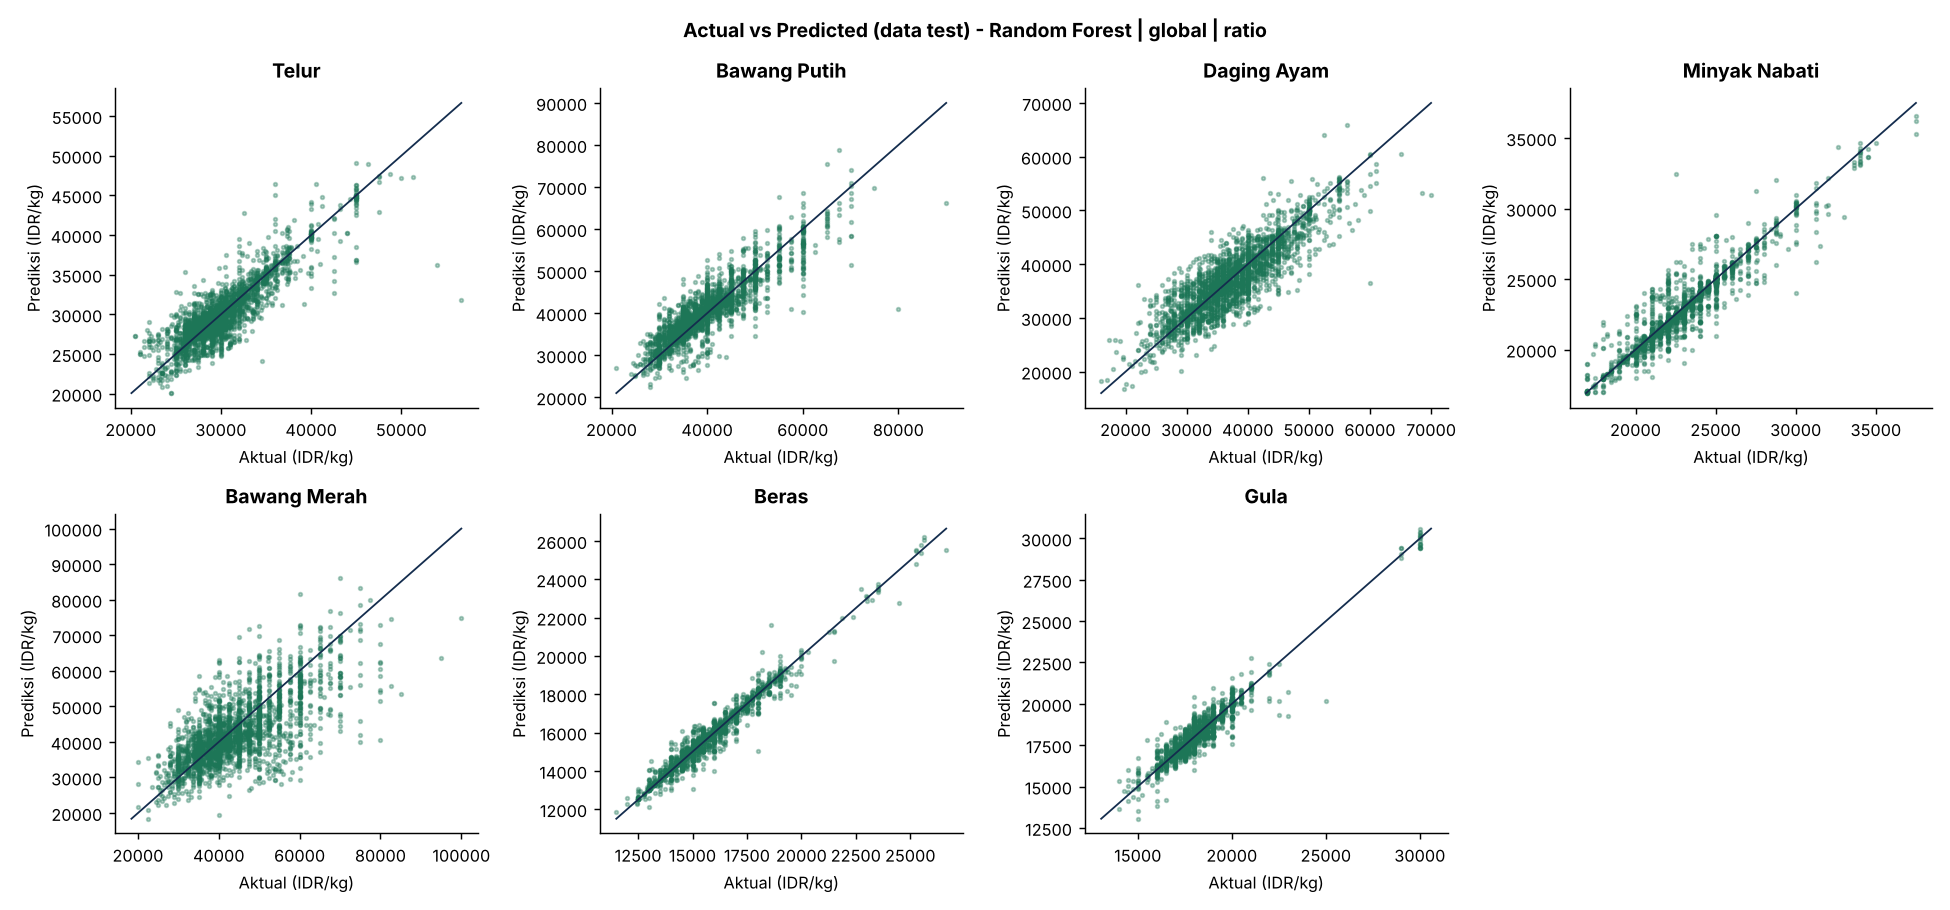

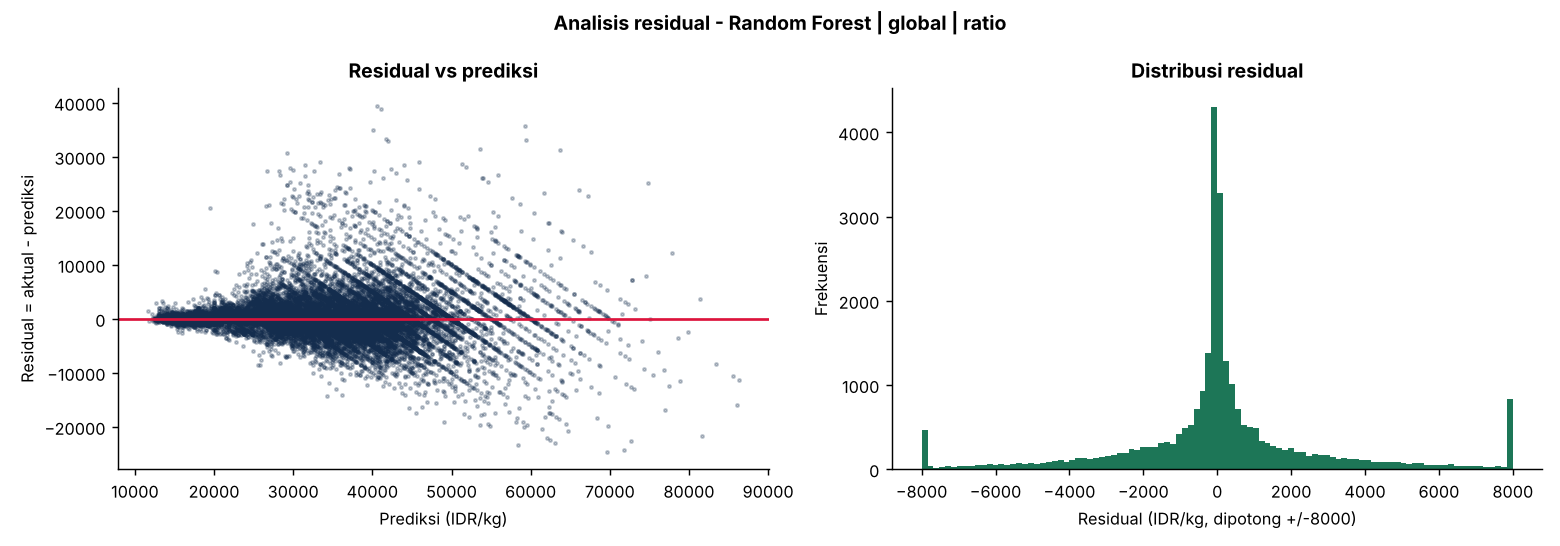

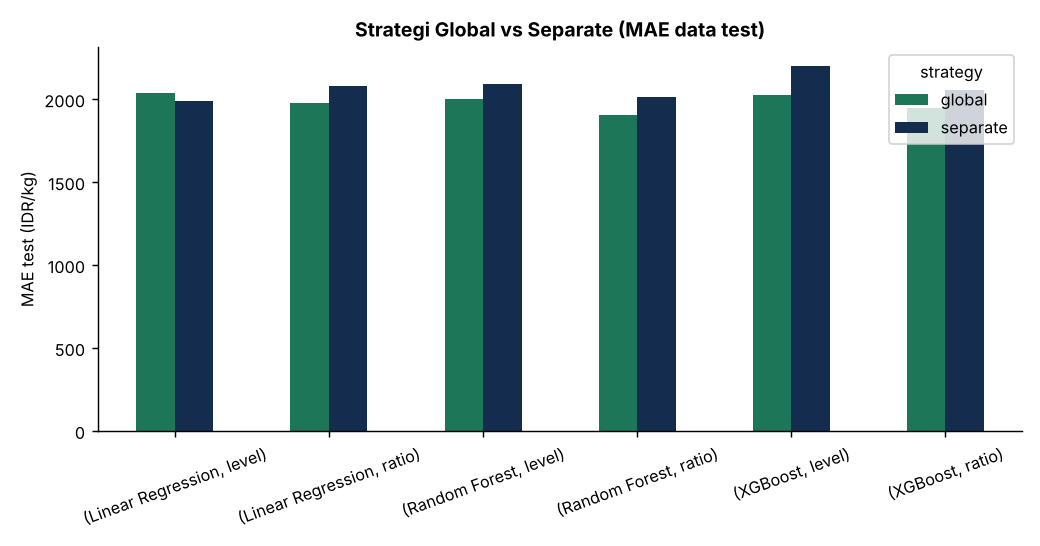

In [5]:
for f in sorted(Path('results/figures').glob('eval_*.png')):
    display(Image(str(f)))

In [6]:
# Verifikasi: model tersimpan = hasil refit (train+validation), dan metrik test di metadata
# berasal dari model yang HANYA dilatih sampai Desember 2023 (bukan dari bundle hasil refit).
from src.feature_engineering import build_features
from src.data_loader import load_long
from src.evaluation import regression_metrics
from src import training as T

feat = build_features(load_long())
train, val, test = T.make_splits(feat)
b = joblib.load('models/best_model.pkl')

# 1) Bundle final harus dilatih pada train + validation (sampai Desember 2024).
#    Karena itu prediksinya pada data test WAJAR berbeda dari metrik test di metadata.
p_refit = T.predict_strategy(b['models'], test, b['strategy'], b['target_mode'])
m_refit = regression_metrics(test['target'], p_refit)
print('Bundle refit di data test:', {k: round(v, 3) for k, v in m_refit.items()})

# 2) Metrik test di metadata harus dapat direproduksi dari model train-only (params sama).
models_pre = T.fit_strategy(train, b['algo'], b['params'], b['strategy'], b['target_mode'])
p_pre = T.predict_strategy(models_pre, test, b['strategy'], b['target_mode'])
m_pre = regression_metrics(test['target'], p_pre)
selisih = abs(m_pre['MAPE_%'] - meta['metrics_test']['MAPE_%'])
print('Reproduksi metrik test metadata -> selisih MAPE:', round(selisih, 3), '%')
print('Prediksi valid (finite & > 0):', bool(np.isfinite(p_refit).all() and (p_refit > 0).all()))

Bundle refit di data test: {'n': 27798, 'MAE': 1893.487, 'RMSE': 3657.252, 'R2': 0.906, 'MAPE_%': 5.111}


Reproduksi metrik test metadata -> selisih MAPE: 0.001 %
Prediksi valid (finite & > 0): True


## Pilihan per komoditas dan rentang 80%

Bahan dengan metode `naive` menampilkan harga terakhir sebagai perkiraan dasar. Cakupan rentang di data test idealnya mendekati 80%.

In [7]:
cm = pd.read_csv('results/commodity_method.csv')
cm[['nama','metode','mape_test_model','mape_test_naive','mape_test_terpilih','band_low_pct','band_high_pct','cakupan_uji_pct']].round(2)

,nama,metode,mape_test_model,mape_test_naive,mape_test_terpilih,band_low_pct,band_high_pct,cakupan_uji_pct
0,Telur,naive,5.02,4.47,4.47,-5.46,4.00,64.39
1,Bawang Putih,naive,6.39,5.34,5.34,-4.76,8.72,66.17
2,Daging Ayam,naive,7.35,7.02,7.02,-6.74,13.21,72.69
3,Minyak Nabati,naive,2.07,1.15,1.15,-0.42,4.35,83.91
4,Bawang Merah,model,12.45,14.31,12.45,-15.03,24.03,78.35
5,Beras,naive,1.29,0.83,0.83,-1.72,1.85,82.61
6,Gula,naive,1.64,1.20,1.20,-2.62,2.81,80.60
